# Lab: Los datos como vectores

**Meta:** representar datos como vectores con NumPy, operar con ellos sin ciclos y comprobar que
el vector media (*mean vector*) es una combinación lineal (*linear combination*) de las
observaciones. Acompaña a la página de
conceptos [Los datos como vectores](l01_concept_vectores_datos.qmd).

> **Cómo usar este laboratorio:** en el sitio del curso esta página es de solo lectura: muestra
> el código junto con lo que produjo. Para ejecutarlo, ábrelo en Google Colab y usa *Archivo,
> Guardar una copia en Drive* antes de trabajar. Ejecuta las celdas en orden, de arriba abajo.

## Preparación

Este laboratorio no instala nada: Colab ya trae NumPy, pandas y Matplotlib. La celda de
preparación importa las bibliotecas, fija la semilla y carga los datos: los pingüinos de Palmer
(licencia CC0), incluidos con el curso. Ejecútala cada vez que abras el laboratorio.

In [1]:
# Preparacion: bibliotecas, semilla y datos. Seguro de ejecutar de nuevo.
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(4031)

# Los pinguinos de Palmer (Gorman, Williams y Fraser, 2014; CC0), copia del curso.
RUTA = Path("data/penguins.csv")
URL = "https://raw.githubusercontent.com/devomh/mate4031-2027/main/u01_vectores/data/penguins.csv"
pinguinos = pd.read_csv(RUTA if RUTA.exists() else URL)

# Las cuatro medidas; se descartan los 2 pinguinos que no tienen medidas.
VARIABLES = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
completos = pinguinos.dropna(subset=VARIABLES).reset_index(drop=True)
X = completos[VARIABLES].to_numpy()
especie = completos["species"].to_numpy()

print("tabla original:", pinguinos.shape)
print("matriz X:", X.shape)

tabla original: (344, 8)
matriz X: (342, 4)


<details><summary>Resultado esperado</summary>

~~~text
tabla original: (344, 8)
matriz X: (342, 4)
~~~
</details>

La tabla original tiene 344 filas y 8 columnas (también la especie, la isla, el sexo y el año).
`X` es la **matriz de datos** (*data matrix*): 342 pingüinos (filas) por 4 variables numéricas (columnas). Cada
fila es un vector de $\mathbb{R}^4$.

## Paso 1: vectores y tablas como arreglos

Un vector es un arreglo (*array*) de NumPy de una dimensión; una tabla, un arreglo de dos. El
atributo `shape` da la forma (*shape*). Con una tabla, `tabla[i]` es la fila `i` (una observación) y
`tabla[:, j]` la columna `j` (una variable). Los índices empiezan en 0.

In [2]:
u = np.array([2, 1])
v = np.array([-1, 3])
print("u =", u, "  forma:", u.shape)

# Los tres pinguinos de la pagina de conceptos: largo del pico y de la aleta (mm).
tres = np.array([[39.1, 181], [51.3, 198], [47.6, 215]])
print("forma de la tabla:", tres.shape)
print("fila 0 (Adelie):", tres[0])
print("columna 1 (aleta):", tres[:, 1])

u = [2 1]   forma: (2,)
forma de la tabla: (3, 2)
fila 0 (Adelie): [ 39.1 181. ]
columna 1 (aleta): [181. 198. 215.]


<details><summary>Resultado esperado</summary>

~~~text
u = [2 1]   forma: (2,)
forma de la tabla: (3, 2)
fila 0 (Adelie): [ 39.1 181. ]
columna 1 (aleta): [181. 198. 215.]
~~~
</details>

La forma `(2,)` dice que `u` tiene 2 componentes. La tabla tiene forma `(3, 2)`: 3
observaciones, cada una en $\mathbb{R}^2$. La fila 0 es un pingüino; la columna 1 reúne la
misma variable de los 3 pingüinos, un vector de $\mathbb{R}^3$. NumPy escribe `181.` porque
toda la tabla se guarda como números decimales.

## Paso 2: operaciones sin ciclos

### Primero, con un ciclo

La suma de vectores es componente a componente, así que se puede escribir con un ciclo:

In [3]:
suma = []
for k in range(len(u)):
    suma.append(u[k] + v[k])
print("u + v =", suma)

u + v = [1, 4]


<details><summary>Resultado esperado</summary>

~~~text
u + v = [1, 4]
~~~
</details>

### Mejor: operaciones vectorizadas

NumPy hace ese ciclo por dentro: sus operaciones son vectorizadas (*vectorized*). `u + v` y `2 * u` actúan componente a componente:

In [4]:
print("u + v  =", u + v)
print("2u     =", 2 * u)
print("2u + v =", 2 * u + v)

u + v  = [1 4]
2u     = [4 2]
2u + v = [3 5]


<details><summary>Resultado esperado</summary>

~~~text
u + v  = [1 4]
2u     = [4 2]
2u + v = [3 5]
~~~
</details>

Son los resultados de la página de conceptos: $\mathbf{u} + \mathbf{v} = (1, 4)$,
$2\mathbf{u} = (4, 2)$ y $2\mathbf{u} + \mathbf{v} = (3, 5)$.

### ¿Por qué es mejor?

Es más corto y se lee como la fórmula. Además es mucho más rápido. Para comprobarlo hace falta
un **control**: el mismo cálculo, $2\mathbf{a} + \mathbf{b}$, hecho de las dos maneras con
vectores de un millón de componentes. Primero se verifica que el resultado es el mismo; después
se comparan los tiempos. El tiempo exacto cambia de una máquina a otra, así que la celda no lo
imprime: comprueba que la versión vectorizada es al menos 5 veces más rápida.

In [5]:
a = rng.normal(size=1_000_000)
b = rng.normal(size=1_000_000)

inicio = time.perf_counter()
c_ciclo = np.array([2 * a[k] + b[k] for k in range(len(a))])
medio = time.perf_counter()
c_vectorizado = 2 * a + b
fin = time.perf_counter()

print("mismo resultado:", np.allclose(c_ciclo, c_vectorizado))
print("vectorizado al menos 5 veces mas rapido:", (medio - inicio) > 5 * (fin - medio))

mismo resultado: True
vectorizado al menos 5 veces mas rapido: True


<details><summary>Resultado esperado</summary>

~~~text
mismo resultado: True
vectorizado al menos 5 veces mas rapido: True
~~~
</details>

Los dos cálculos coinciden, y la versión vectorizada es mucho más rápida. Cuántas veces más
depende de la máquina y de la corrida; si quieres ver tu propia cifra, imprime
`(medio - inicio) / (fin - medio)`.

## Paso 3: el vector media como combinación lineal

En la página de conceptos calculaste a mano la media de los tres pingüinos,
$\frac{1}{3}\mathbf{x}_1 + \frac{1}{3}\mathbf{x}_2 + \frac{1}{3}\mathbf{x}_3 = (46.0, 198.0)$.
Aquí está la misma combinación lineal en NumPy, comparada con el método `mean`:

In [6]:
media_tres = (1/3) * tres[0] + (1/3) * tres[1] + (1/3) * tres[2]
print("combinacion lineal:", media_tres)
print("tres.mean(axis=0): ", tres.mean(axis=0))

combinacion lineal: [ 46. 198.]
tres.mean(axis=0):  [ 46. 198.]


<details><summary>Resultado esperado</summary>

~~~text
combinacion lineal: [ 46. 198.]
tres.mean(axis=0):  [ 46. 198.]
~~~
</details>

`axis=0` quiere decir "a lo largo de las filas": promedia las filas y deja una media por
columna, es decir, un vector de $\mathbb{R}^2$.

Ahora con los 342 pingüinos. Sumar las 342 filas y dividir entre $n$ es la combinación lineal
con todos los coeficientes iguales a $1/n$. Completa la línea marcada, quítale el `#` a las
tres líneas y ejecuta la celda:

In [7]:
n = X.shape[0]
# media = ____ / n          # <- completa: la suma de las filas, X.sum(axis=...)
# print("combinacion lineal:", np.round(media, 1))
# print("coincide con X.mean(axis=0):", np.allclose(media, X.mean(axis=0)))

<details><summary>Resultado esperado</summary>

~~~text
combinacion lineal: [  43.9   17.2  200.9 4201.8]
coincide con X.mean(axis=0): True
~~~
</details>

## Paso 4: los 342 pingüinos

El vector media tiene una componente por variable. En la figura, cada punto es un pingüino visto
en dos de sus cuatro componentes (el largo del pico y el de la aleta), y la X marca esas dos
componentes del vector media.

vector media: [  43.9   17.2  200.9 4201.8]


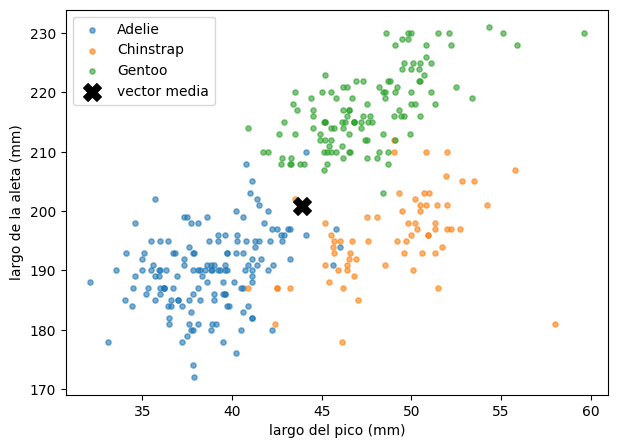

In [8]:
media = X.mean(axis=0)
print("vector media:", np.round(media, 1))

fig, ax = plt.subplots(figsize=(7, 5))
for nombre, color in [("Adelie", "tab:blue"), ("Chinstrap", "tab:orange"),
                      ("Gentoo", "tab:green")]:
    filas = X[especie == nombre]
    ax.scatter(filas[:, 0], filas[:, 2], s=14, alpha=0.6, color=color, label=nombre)
ax.scatter(media[0], media[2], s=160, marker="X", color="black", label="vector media")
ax.set_xlabel("largo del pico (mm)")
ax.set_ylabel("largo de la aleta (mm)")
ax.legend()
plt.show()

<details><summary>Resultado esperado</summary>

~~~text
vector media: [  43.9   17.2  200.9 4201.8]
~~~
</details>

La figura aparece al ejecutar la celda en Colab; la vista de solo lectura del sitio muestra solo
la salida de texto.

**Cómo leer la figura.** Cada especie forma su propia nube, y la media cae entre las nubes,
donde hay pocos pingüinos. La media resume la tabla, pero no describe a un pingüino típico de
ninguna especie: es un punto calculado, no un animal medido.

La media de una sola especie es la media de sus filas. `especie == "Gentoo"` es un arreglo de
`True` y `False`, y `X[especie == "Gentoo"]` se queda con las filas de los Gentoo. Completa la
línea marcada, quita los `#` y ejecuta:

In [9]:
# for nombre in ["Adelie", "Chinstrap", "Gentoo"]:
#     media_especie = ____      # <- completa: la media de las filas de esa especie
#     print(nombre, np.round(media_especie, 1))

<details><summary>Resultado esperado</summary>

~~~text
Adelie [  38.8   18.3  190.  3700.7]
Chinstrap [  48.8   18.4  195.8 3733.1]
Gentoo [  47.5   15.   217.2 5076. ]
~~~
</details>

## Tu turno

### Ejercicio 1: la diferencia entre dos especies

Calcula el vector diferencia entre la media de los Gentoo y la media de los Adelie (Gentoo menos
Adelie) y redondéalo a un decimal. **Pista:** resta las medias sin redondear y redondea al final;
si restas las medias redondeadas del paso 4, la segunda y la cuarta componente salen distintas.
Después contesta: ¿qué dice cada componente?

In [10]:
# TODO: tu codigo aqui

<details><summary>Resultado esperado</summary>

~~~text
[   8.7   -3.4   27.2 1375.4]
~~~

Un Gentoo típico tiene el pico 8.7 mm más largo y 3.4 mm menos profundo, la aleta 27.2 mm más
larga y 1375.4 g más de masa que un Adelie típico. Cada componente conserva sus unidades: la
diferencia es una resta componente a componente.
</details>

### Ejercicio 2: los textos también son vectores

Fija un vocabulario de cuatro palabras. La función `conteos` convierte un texto en el vector que
cuenta cuántas veces aparece cada palabra del vocabulario. Comprueba que el vector del texto
unido `d1 + " " + d2` es la suma de los vectores de `d1` y `d2`, y calcula `3 * conteos(d1)`.
¿Qué texto tendría ese vector?

In [11]:
vocabulario = ["vector", "datos", "matriz", "suma"]
d1 = "una matriz de datos tiene un vector de datos por fila"
d2 = "la suma de un vector y otro vector es un vector"


def conteos(texto):
    palabras = texto.split()
    return np.array([palabras.count(w) for w in vocabulario])


# TODO: imprime conteos(d1), conteos(d2), conteos(d1 + " " + d2) y conteos(d1) + conteos(d2),
# compara los dos ultimos con np.array_equal, e imprime 3 * conteos(d1)

<details><summary>Resultado esperado</summary>

~~~text
d1: [1 2 1 0]
d2: [3 0 0 1]
texto unido: [4 2 1 1]
suma de vectores: [4 2 1 1]
iguales: True
3 * d1: [3 6 3 0]
~~~

Unir dos textos suma sus conteos, palabra por palabra: la suma de vectores tiene un significado
concreto. `3 * conteos(d1)` es el vector de `d1` repetido tres veces. Una colección de textos es
una matriz de datos con una fila por texto y una columna por palabra.
</details>

### Ejercicio 3: ¿qué operaciones tienen sentido?

La columna 3 de `X` es la masa en gramos. Multiplícala por el escalar $0.001$ para pasarla a
kilogramos y muestra los tres primeros valores. Después decide, y justifica en una oración,
si tienen sentido estas dos operaciones, que NumPy calcula sin quejarse: `X[:, 0] + X[:, 3]`
(el largo del pico más la masa) y `X[:, 0] + X[:, 2]` (el largo del pico más el de la aleta).

In [12]:
# TODO: tu codigo aqui

<details><summary>Resultado esperado</summary>

~~~text
[3.75 3.8  3.25]
~~~

Un múltiplo escalar de una columna cambia su escala: 3750 g son 3.75 kg. Ninguna de las dos
sumas tiene sentido. El pico más la masa mezcla milímetros con gramos: NumPy suma los números,
pero el resultado no mide nada. El pico más la aleta tiene las mismas unidades, pero son dos
variables distintas, y su suma no es la medida de ninguna parte del pingüino. Que una operación
se pueda calcular, y aun que sus unidades coincidan, no quiere decir que tenga sentido.
</details>

## Resumen

- Un vector es un arreglo de una dimensión; la matriz de datos `X`, uno de dos, con forma
  `(n, p)`: filas = observaciones, columnas = variables.
- Las operaciones de NumPy son componente a componente y no necesitan ciclos: dan el mismo
  resultado que el ciclo y son mucho más rápidas.
- El vector media, `X.mean(axis=0)`, es la combinación lineal de las filas con coeficientes
  $1/n$.
- Próxima lección (L02): el producto punto, las normas y las distancias, para medir qué tan
  parecidos son dos pingüinos.